# Third Lab — Structured RAVDESS Audio Analysis Pipeline

**Course:** Computational Foundations for Biomedical Engineering  
**Deliverable:** English Jupyter report + version-controlled modular Python project

This notebook formalizes the previous audio-processing work as a reproducible pipeline with **preprocessing**, **analysis**, and **visualization** modules, and studies their algorithmic complexity and computational optimization. It runs offline on a small **synthetic fixture**, supplied in `data/raw/synthetic_demo.zip`, whose RAVDESS-style filenames are only for software testing. The real dataset must be supplied separately for scientific analyses. A high demo classification score cannot be construed as a result about real speech, depression, or medical screening.

**Evaluation components:** directory layout (10%); modules (30%); line-level and global complexity notebooks (25%); optimization and timing comparison (20%); requirements, README and docstrings (15%).

## 1. Setup and source structure

The project is runnable from its extracted root or from the `notebooks/` folder. `run_pipeline.py` orchestrates three separated modules; see their README files and `complexity_analysis.ipynb` for the complete line-level analysis.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the extracted project root or notebooks/ folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from run_pipeline import run
from benchmark import benchmark
from src.preprocessing.audio import load_paired_audios, truncate_matched_groups
from src.analysis.features import window_features_reference, window_features_vectorized
from src.analysis.statistics import summarize_reference, summarize_optimized

DEMO = ROOT / "data/raw/synthetic_demo.zip"
print("Project root:", ROOT)
print("Offline demonstration file available:", DEMO.is_file())

Project root: /mnt/data/RAVDESS_Lab3
Offline demonstration file available: True


## 2. Methods and module responsibilities

**Preprocessing:** decode matched neutral and sad clips from ZIP without writing per-clip temporary files. Match actor and speech metadata by filename rather than assuming fixed offsets. Truncate all included recordings to a shared minimum sample count.

**Analysis:** create short-time frames using 25 ms windows with a 10 ms hop. Calculate RMS, peak amplitude, zero crossing rate, and Hann-windowed spectral centroid. Estimate framewise F0 with pYIN using longer frames for the 65–500 Hz range. Summarize each actor with mean, sample std, median, min, max, and range in a `(Characteristic, Statistic)` column MultiIndex. Perform paired Shapiro and Wilcoxon tests (Holm-adjusted) and leave-one-actor-out logistic regression without actor leakage.

**Visualization:** save paired actor comparisons and ROC curves to `results/figures/`. This separation keeps the production algorithms outside the exploratory notebook.

In [2]:
actors, audio_groups, fs = load_paired_audios(DEMO, n_actors=6)
matrices = truncate_matched_groups(audio_groups)
print("Matched actors:", actors)
print("Sampling rate:", fs, "Hz")
print("Neutral and sad matrix shapes:", matrices["Neutral"].shape, matrices["Sad"].shape)
assert matrices["Neutral"].shape == matrices["Sad"].shape

Matched actors: ['01', '02', '03', '04', '05', '06']
Sampling rate: 8000 Hz
Neutral and sad matrix shapes: (6, 12144) (6, 12144)


## 3. Complexity — per line and globally

The three required *line-by-line* notebooks are supplied in `src/preprocessing/complexity_analysis.ipynb`, `src/analysis/complexity_analysis.ipynb`, and `src/visualization/complexity_analysis.ipynb`. They enumerate nonempty source lines from each module and state the dominant cost of every operation. See `docs/complexity_summary.md` for derivations and assumptions.

Set `R=2A`, `W≈N/H`, `K=0.025fs`, `P≈2fs/65` rounded up to a power of two, and `d` preselected model inputs. Framing is a view (`O(1)`); amplitude reductions cost `O(RWK)`; short-time FFTs cost `O(RWK log K)`. The **pYIN library cost is represented explicitly** by `T_pYIN(R,N,P,H)`, rather than asserting an unsupported bound. Paired tests require roughly `O(FSA log A)` plus Holm corrections, and actor-held-out classification requires `M×A` model fits.

**Combined:** `O(Z + L + RN + RWK log K + FRW log W + FSA log A + MA·T_fit(2A−2,d)) + T_pYIN(R,N,P,H)` plus image rendering. These are upper-bound descriptions, not a prediction of wall-clock seconds.

## 4. Optimization and correctness check

**Before:** reference ZIP extraction writes temporary WAVs; the instructional baseline loops over every actor/window; the older table builder concatenates all window-level feature data. **After:** decode ZIP entries in memory, compute features with NumPy vectorization (already used in the preceding assignment), and build the summary per feature to reduce stacked intermediate memory. There is no claim of a different big-O bound for the FFT stage. pYIN remains identical and is excluded from the isolated feature timing test.

In [3]:
# Compare equivalent calculations on the very same demo recordings.
reference = window_features_reference(matrices["Neutral"], fs, include_pitch=False)
vectorized = window_features_vectorized(matrices["Neutral"], fs, include_pitch=False)
for feature in reference:
    assert __import__("numpy").allclose(reference[feature], vectorized[feature], atol=1e-4, rtol=1e-5)

import pandas as pd
pd.testing.assert_frame_equal(
    summarize_reference(reference, actors),
    summarize_optimized(vectorized, actors),
    check_exact=False, atol=1e-4, rtol=1e-5
)
print("Reference and optimized features/tables agree numerically.")

Reference and optimized features/tables agree numerically.


,Stage,Reference [s],Optimized [s],Speedup (reference / optimized)
0,WAV ingestion,0.00202,0.00172,1.17385
1,Four acoustic features (excluding identical pYIN),0.02164,0.00106,20.50177
2,Feature summary table,0.00287,0.00536,0.53644


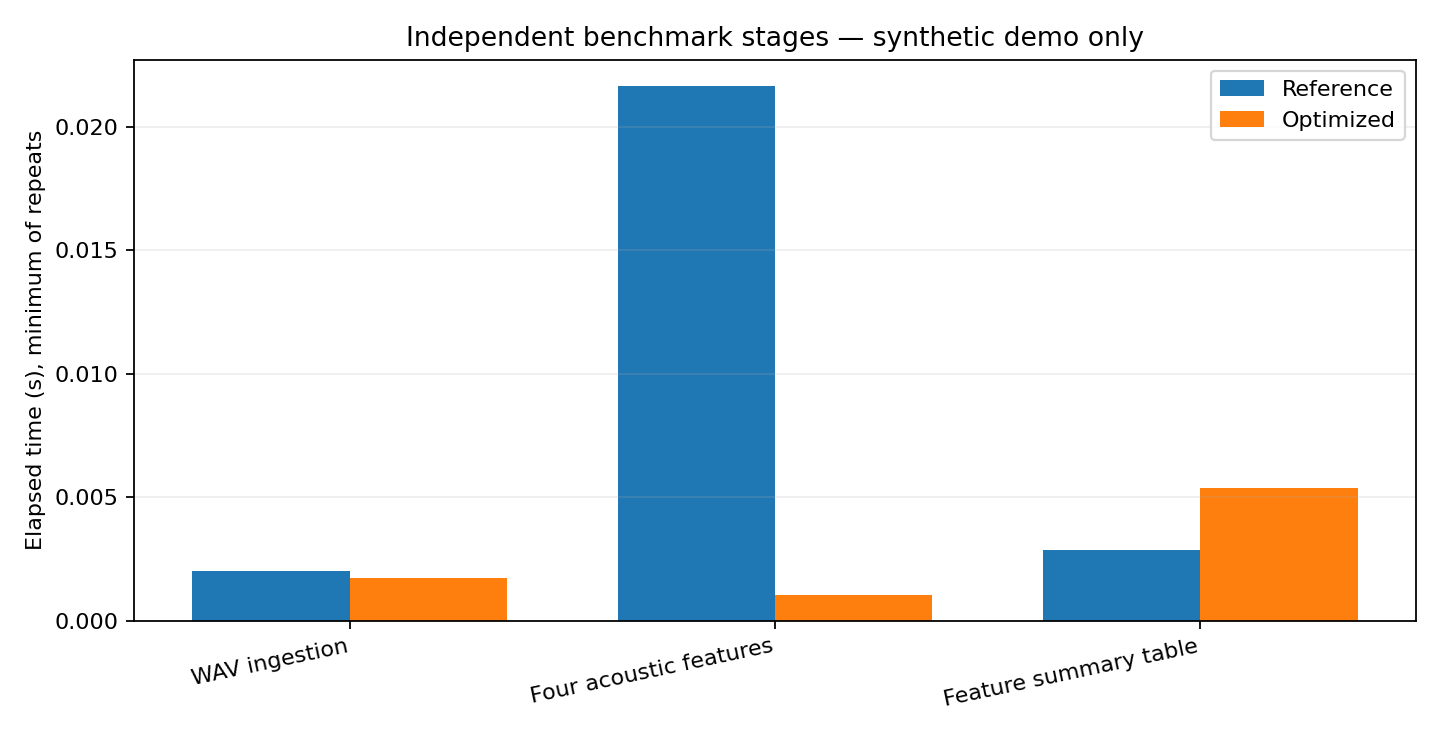

In [4]:
# Measured speeds; best of three repeats, for these demo signals only.
timings = benchmark(DEMO, n_actors=6, repeats=3)
display(timings.round(5))
from src.visualization.plots import plot_benchmark_comparison
bench_figure = plot_benchmark_comparison(timings, ROOT / "results" / "figures")
display(Image(filename=str(bench_figure), width=750))

The time complexity is unchanged for the main FFT calculations; the measured advantage of vectorization comes from fewer interpreted Python iterations. In-memory I/O reduces unnecessary disk operations. The per-feature summary builder may be slower on small inputs but uses less *peak intermediate* window-table memory. No real RAVDESS or clinical conclusions follow from a speed benchmark on synthetic audio.

## 5. End-to-end demo: statistics and separability

This code executes the same pipeline that can later be applied to the authentic archive. The actors are paired, features have a two-level column MultiIndex, Wilcoxon is paired and Holm-adjusted, and the classifier uses Leave-One-Group-Out folds by actor. The demo only tests implementation and reproducibility.

In [5]:
analysis = run(DEMO, n_actors=6, output_dir=ROOT / "results")
print("DataFrame levels:", analysis["summaries"]["Neutral"].columns.names)
display(analysis["summaries"]["Neutral"].iloc[:3, :12].round(3))
display(analysis["tests"].head(8).round(4))
display(analysis["scores"].round(4))

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DataFrame levels: ['Characteristic', 'Statistic']


Characteristic    RMS                     ...   Peak                   
Statistic        Mean    Std Median  Min  ... Median  Min    Max  Range
Actor                                     ...                          
01              0.059  0.036  0.056  0.0  ...  0.099  0.0  0.173  0.173
02              0.063  0.038  0.064  0.0  ...  0.114  0.0  0.172  0.172
03              0.065  0.038  0.067  0.0  ...  0.119  0.0  0.173  0.173

[3 rows x 12 columns]

N pairs  Shapiro p  Wilcoxon p  Holm-adjusted p
Feature Statistic                                                 
RMS     Mean             6     0.7563      0.0312           0.9375
        Std              6     0.1330      0.0312           0.9375
        Median           6     0.9974      0.0312           0.9375
        Min              6        NaN      1.0000           1.0000
        Max              6     0.5040      0.0312           0.9375
        Range            6     0.5040      0.0312           0.9375
Peak    Mean             6     0.1577      0.0312           0.9375
        Std              6     0.2146      0.0312           0.9375

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic regression,0.5833,0.6,0.5,0.5455,0.7222
Standardized logistic,1.0000,1.0,1.0,1.0000,1.0000


Saved figures: ['results/figures/paired_rms_mean.png', 'results/figures/paired_zcr_mean.png', 'results/figures/paired_spectral_centroid_median.png', 'results/figures/paired_f0_median.png', 'results/figures/roc_grouped_cv.png']


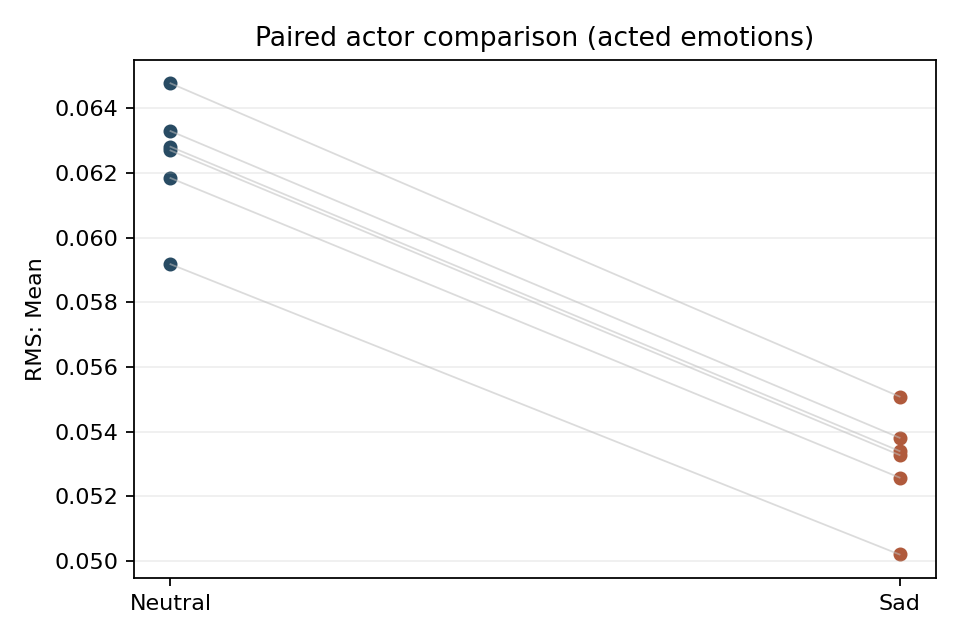

In [6]:
# Display one saved plot. All separate plots are saved in results/figures.
print("Saved figures:", [str(p.relative_to(ROOT)) for p in analysis["figures"]])
display(Image(filename=str(analysis["figures"][0]), width=550))

## 6. Discussion

The reproducible software workflow now uses actor-matched identifiers, no temporary WAV extraction, a consistent two-condition length policy, explicit F0 treatment, corrected paired testing, a column MultiIndex suitable for model input, and grouped cross-validation. The optimization benchmark is meaningful only for the particular dataset sizes and hardware on which it is run. pYIN is an unchanged, expensive library call and its internal runtime must not be hidden inside a misleading FFT-only big-O.

The input lacks clinical diagnosis labels. RAVDESS is performed speech, and the bundled fixture is not even speech: **the only supported interpretation of its output is that the pipeline can execute and reproduce its computations**. Real results would require the authentic ZIP and reexecution. No full-dataset conclusions can be drawn from the synthetic demo.

## 7. Conclusions

The Third Lab's five tasks are represented: a well-organized repository, three scientific-programming modules, line-by-line plus global complexity audits, equivalent baseline/optimized implementations with measured timings, and requirements/README/docstrings/notebooks. The methods form a reproducible starting point for genuine acted-emotion analysis, not a validated depression detector.

## References (APA 7)

Livingstone, S. R., & Russo, F. A. (2018). The Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS): A dynamic, multimodal set of facial and vocal expressions in North American English. *PLOS ONE, 13*(5), Article e0196391. https://doi.org/10.1371/journal.pone.0196391

Mao, K., Wu, Y., & Chen, J. (2023). A systematic review on automated clinical depression diagnosis. *npj Mental Health Research, 2*, Article 20. https://doi.org/10.1038/s44184-023-00040-z